# CRISP-DM Phase 4 – Modeling

**Goal:** compare Random Forest, XGBoost and LightGBM against a linear baseline, select the best one and define the
decision rule. The logic lives in `src/train.py`; this notebook calls the same functions.

The official model (`models/model.pkl`) is generated with `python -m src.train`.

Previous phase: `03_data_preparation.ipynb` · Next phase: `05_evaluation.ipynb`

In [1]:
import sys
sys.path.insert(0, "..")  # project root, to import the src package

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split

from src.preprocessing import CLASSES
from src.sinan import TRAIN_YEAR, load_dataset
from src.train import (DENGUE, SEED, build_models, choose_best, choose_dengue_threshold, cross_validation)

X, y, _ = load_dataset(TRAIN_YEAR)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train {len(X_train):,} | test {len(X_test):,} (the test set is not used until Phase 5)")

train 96,000 | test 24,000 (the test set is not used until Phase 5)


## 4.1 Test design and candidates

- **5-fold stratified cross-validation** on the training set.
- **Selection metric: macro ROC-AUC (one-vs-rest)**; ties within 0.005 broken by the lower log-loss.
- **Logistic Regression** (with imputation and scaling) is the baseline. **Random Forest**, **XGBoost** and **LightGBM** are
  the candidates: tree ensembles capture interactions between findings (e.g. *rash without joint pain*), need no scaling and
  handle missing values natively.

In [2]:
models = build_models()
for name, model in models.items():
    print(f"{name}: {model}")

Logistic Regression: Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('scale', StandardScaler()),
                ('clf', LogisticRegression(max_iter=2000))])
Random Forest: RandomForestClassifier(max_depth=14, min_samples_leaf=30, n_estimators=200,
                       n_jobs=-1, random_state=42)
XGBoost: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=5, missing=nan, monotone_constraints=Non

In [3]:
cv = cross_validation(models, X_train, y_train)
cv[["roc_auc", "roc_auc_std", "balanced_accuracy", "f1_macro", "log_loss"]]

  Logistic Regression  ROC-AUC 0.704  balanced acc 0.535


  Random Forest        ROC-AUC 0.839  balanced acc 0.672


  XGBoost              ROC-AUC 0.857  balanced acc 0.692


  LightGBM             ROC-AUC 0.860  balanced acc 0.695


,roc_auc,roc_auc_std,balanced_accuracy,f1_macro,log_loss
model,,,,,
Logistic Regression,0.704,1.117e-03,0.535,0.526,0.967
Random Forest,0.839,1.832e-03,0.672,0.669,0.781
XGBoost,0.857,1.088e-03,0.692,0.690,0.711
LightGBM,0.860,9.261e-04,0.695,0.694,0.704


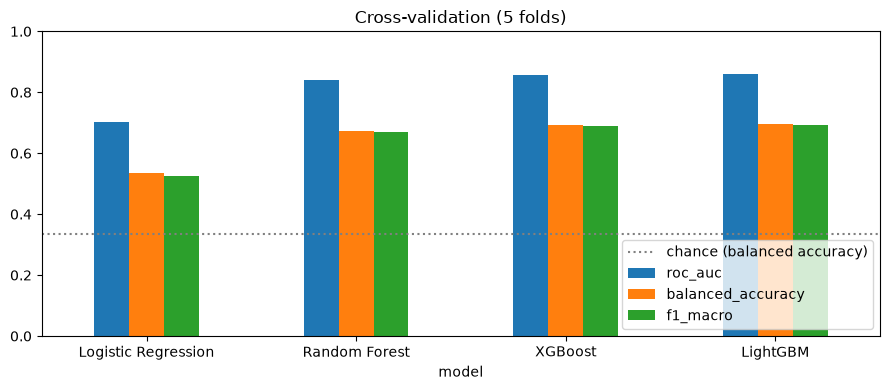

Selected model: LightGBM


In [4]:
ax = cv[["roc_auc", "balanced_accuracy", "f1_macro"]].plot.bar(figsize=(9, 4), rot=0)
ax.axhline(1 / 3, color="gray", ls=":", label="chance (balanced accuracy)"); ax.set_ylim(0, 1)
ax.set_title("Cross-validation (5 folds)"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
best_name = choose_best(cv)
print("Selected model:", best_name)

## 4.2 Decision rule: the dengue alert

Suggesting simply the most likely diagnosis treats all errors equally. Missing dengue is the most dangerous error, so dengue
is suggested whenever **P(dengue) ≥ threshold**, choosing the highest threshold that keeps dengue recall ≥ 80 % on
*out-of-fold* predictions of the training set.

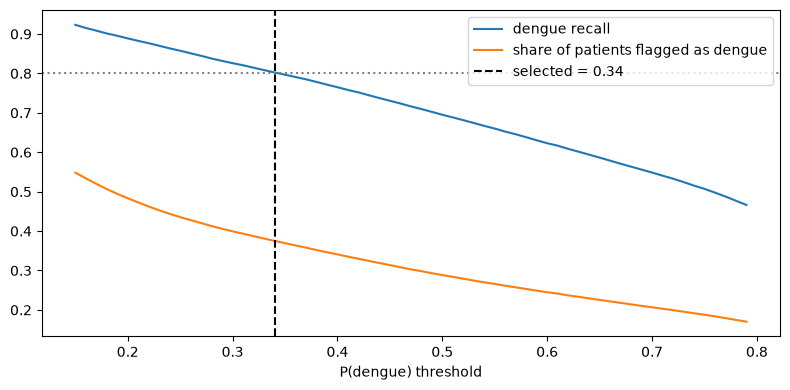

Dengue alert threshold: 0.34


In [5]:
threshold, oof = choose_dengue_threshold(models[best_name], X_train, y_train)
grid = np.arange(0.15, 0.80, 0.01)
curve = pd.DataFrame({
    "dengue recall": [recall_score(y_train == DENGUE, oof[:, DENGUE] >= t) for t in grid],
    "share of patients flagged as dengue": [(oof[:, DENGUE] >= t).mean() for t in grid],
}, index=grid)
ax = curve.plot(figsize=(8, 4)); ax.axvline(threshold, color="k", ls="--", label=f"selected = {threshold}")
ax.axhline(0.8, color="gray", ls=":"); ax.set_xlabel("P(dengue) threshold"); ax.legend(); plt.tight_layout(); plt.show()
print("Dengue alert threshold:", threshold)

## 4.3 Phase output

- Model comparison table and selected model.
- Dengue alert threshold.

The full evaluation on unseen data is in `05_evaluation.ipynb`.